In [2]:
!pip install -q datasets pandas

In [4]:
import pandas as pd

url = "https://zenodo.org/records/7928582/files/IMDB%20Dataset.csv?download=1"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Total rows:", len(df))
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Total rows: 50000
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
# Check dataset size and column details
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 reviews:")
display(df.head())

Number of rows: 50000
Number of columns: 2

Column names:
['review', 'sentiment']

First 5 reviews:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
# Count positive and negative reviews
print("Sentiment Counts:")
print(df["sentiment"].value_counts())

# Calculate percentages
print("\nSentiment Percentages:")
print(df["sentiment"].value_counts(normalize=True) * 100)

Sentiment Counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sentiment Percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


In [7]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

# Remove duplicate rows
df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))

Total duplicate rows: 418
Rows after removing duplicates: 49582


In [8]:
# Calculate the number of words in each review
df["word_count"] = df["review"].astype(str).apply(
    lambda review: len(review.split())
)

# Display the first 5 reviews with word counts
print(df[["review", "word_count"]].head())

# Basic statistics
print("\nWord Count Statistics:")
print(df["word_count"].describe())

                                              review  word_count
0  One of the other reviewers has mentioned that ...         307
1  A wonderful little production. <br /><br />The...         162
2  I thought this was a wonderful way to spend ti...         166
3  Basically there's a family where a little boy ...         138
4  Petter Mattei's "Love in the Time of Money" is...         230

Word Count Statistics:
count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: word_count, dtype: float64


In [9]:
# Calculate word count statistics
mean_words = df["word_count"].mean()
median_words = df["word_count"].median()
mode_words = df["word_count"].mode()[0]
variance_words = df["word_count"].var()
std_words = df["word_count"].std()
skewness_words = df["word_count"].skew()

print("Mean:", mean_words)
print("Median:", median_words)
print("Mode:", mode_words)
print("Variance:", variance_words)
print("Standard Deviation:", std_words)
print("Skewness:", skewness_words)

Mean: 231.35016739945948
Median: 173.0
Mode: 127
Variance: 29426.664496351757
Standard Deviation: 171.54201962304091
Skewness: 2.1680977707416025


In [10]:
# Compare average word count by sentiment
average_words = df.groupby("sentiment")["word_count"].mean()

print("Average Word Count by Sentiment:")
print(average_words)

# Compare median word count by sentiment
median_words = df.groupby("sentiment")["word_count"].median()

print("\nMedian Word Count by Sentiment:")
print(median_words)

Average Word Count by Sentiment:
sentiment
negative    229.596607
positive    233.090620
Name: word_count, dtype: float64

Median Word Count by Sentiment:
sentiment
negative    174.0
positive    172.0
Name: word_count, dtype: float64


In [11]:
# Install and import NLP tools
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLP libraries are ready!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


NLP libraries are ready!


In [12]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Prepare NLP tools
lemmatizer = WordNetLemmatizer()

# Keep important negative words
stop_words = set(stopwords.words("english"))
stop_words = stop_words - {
    "not", "no", "nor", "never", "neither", "cannot"
}

def clean_review(text):
    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", str(text))

    # Convert text to lowercase
    text = text.lower()

    # Split text into words
    tokens = word_tokenize(text)

    # Remove stopwords and non-alphabetic tokens
    tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    # Convert words to their base forms
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Join words back into a sentence
    return " ".join(tokens)

print("Text cleaning function created successfully!")

Text cleaning function created successfully!


In [13]:
# Select one sample review
sample = str(df["review"].iloc[0])

# Stage 1: Original review
print("1. Original Review:\n", sample[:500])

# Stage 2: Remove HTML tags
html_removed = re.sub(r"<.*?>", " ", sample)
print("\n2. HTML Tags Removed:\n", html_removed[:500])

# Stage 3: Convert to lowercase
lower_text = html_removed.lower()
print("\n3. Lowercase Text:\n", lower_text[:500])

# Stage 4: Tokenize
tokens = word_tokenize(lower_text)
print("\n4. Tokenized Words:\n", tokens[:40])

# Stage 5: Remove stopwords
filtered_tokens = [
    word for word in tokens
    if word.isalpha() and word not in stop_words
]
print("\n5. Stopwords Removed:\n", filtered_tokens[:40])

# Stage 6: Lemmatize
lemmatized_tokens = [
    lemmatizer.lemmatize(word) for word in filtered_tokens
]
print("\n6. Lemmatized Words:\n", lemmatized_tokens[:40])

1. Original Review:
 One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

2. HTML Tags Removed:
 One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.  The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of 

In [14]:
import time

# Select the first 1,000 reviews
sample_reviews = df["review"].head(1000)

# Measure cleaning time
start_time = time.time()

cleaned_sample = sample_reviews.apply(clean_review)

end_time = time.time()

# Display results
print("Reviews processed:", len(cleaned_sample))
print("Time taken:", round(end_time - start_time, 2), "seconds")
print("Sample cleaned review:")
print(cleaned_sample.iloc[0])

Reviews processed: 1000
Time taken: 3.47 seconds
Sample cleaned review:
one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privacy not high agenda em city home many aryan muslim gangsta latino christian italian irish scuffle death stare dodgy dealing shady agreement never far away would say main appeal show due fact go show would dare forget pretty picture painted mainstream audience forget charm forget romance oz mess around first episode ever saw struck nasty surreal could say ready watched developed taste oz got accustomed high level graphic violence not violence injustice crooked guard sold nickel inmate kill order get away well mann

In [15]:
import time

# Select the first 1,000 reviews
sample_reviews = df["review"].head(1000)

# Measure cleaning time
start_time = time.time()

cleaned_sample = sample_reviews.apply(clean_review)

end_time = time.time()

# Display results
print("Reviews processed:", len(cleaned_sample))
print("Time taken:", round(end_time - start_time, 2), "seconds")
print("Sample cleaned review:")
print(cleaned_sample.iloc[0])

Reviews processed: 1000
Time taken: 1.95 seconds
Sample cleaned review:
one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privacy not high agenda em city home many aryan muslim gangsta latino christian italian irish scuffle death stare dodgy dealing shady agreement never far away would say main appeal show due fact go show would dare forget pretty picture painted mainstream audience forget charm forget romance oz mess around first episode ever saw struck nasty surreal could say ready watched developed taste oz got accustomed high level graphic violence not violence injustice crooked guard sold nickel inmate kill order get away well mann

In [17]:
# Check the existing columns
print(df.columns.tolist())

['review', 'sentiment', 'word_count']


In [18]:
# Create the missing cleaned_review column
df["cleaned_review"] = df["review"].apply(clean_review)

print("Text cleaning completed!")
print("Total reviews:", len(df))
print("Empty reviews:", (df["cleaned_review"].str.strip() == "").sum())

Text cleaning completed!
Total reviews: 49582
Empty reviews: 0


In [19]:
from sklearn.model_selection import train_test_split

# Input: cleaned movie reviews
X = df["cleaned_review"]

# Output: sentiment labels
y = df["sentiment"].str.lower().str.strip()

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining sentiment counts:")
print(y_train.value_counts())

print("\nTesting sentiment counts:")
print(y_test.value_counts())

Training reviews: 39665
Testing reviews: 9917

Training sentiment counts:
sentiment
positive    19907
negative    19758
Name: count, dtype: int64

Testing sentiment counts:
sentiment
positive    4977
negative    4940
Name: count, dtype: int64


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numerical features
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.8,
    max_features=50000,
    sublinear_tf=True
)

# Learn vocabulary from training data only
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training matrix shape: (39665, 50000)
Testing matrix shape: (9917, 50000)


In [21]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
model = MultinomialNB(alpha=0.5)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [23]:
from sklearn.metrics import accuracy_score

# Predict sentiment for test reviews
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("Baseline Accuracy: 50%")

Model Accuracy: 88.45 %
Baseline Accuracy: 50%


In [24]:
from sklearn.metrics import classification_report

print("Classification Report:\n")

print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

    negative       0.89      0.88      0.88      4940
    positive       0.88      0.89      0.89      4977

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



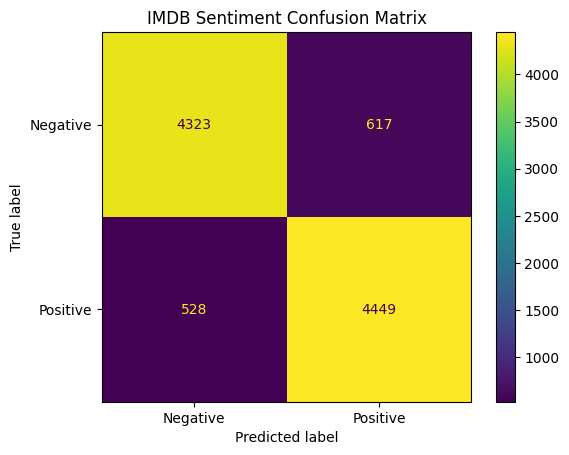

Confusion Matrix Values:
[[4323  617]
 [ 528 4449]]


In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "positive"]
)

# Display confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display_matrix.plot()
plt.title("IMDB Sentiment Confusion Matrix")
plt.show()

print("Confusion Matrix Values:")
print(cm)

In [26]:
import numpy as np

# Get all words and bigrams learned by TF-IDF
feature_names = np.array(tfidf.get_feature_names_out())

# Get log probabilities for each sentiment
class_names = list(model.classes_)
negative_index = class_names.index("negative")
positive_index = class_names.index("positive")

positive_scores = model.feature_log_prob_[positive_index]
negative_scores = model.feature_log_prob_[negative_index]

# 20 most positive words or phrases
top_positive = np.argsort(positive_scores)[-20:][::-1]

print("Top 20 Positive Words/Phrases:")
for i in top_positive:
    print(feature_names[i], round(positive_scores[i], 3))

# 20 most negative words or phrases
top_negative = np.argsort(negative_scores)[-20:][::-1]

print("\nTop 20 Negative Words/Phrases:")
for i in top_negative:
    print(feature_names[i], round(negative_scores[i], 3))

Top 20 Positive Words/Phrases:
film -6.028
movie -6.031
one -6.319
not -6.343
great -6.473
like -6.57
good -6.576
time -6.588
story -6.593
see -6.639
character -6.688
well -6.691
love -6.765
also -6.768
really -6.795
best -6.806
get -6.828
make -6.828
would -6.84
life -6.844

Top 20 Negative Words/Phrases:
movie -5.847
film -6.101
not -6.185
one -6.34
like -6.37
bad -6.391
no -6.505
even -6.529
would -6.546
good -6.597
time -6.621
could -6.672
character -6.673
get -6.677
really -6.679
make -6.68
scene -6.788
acting -6.792
see -6.793
plot -6.797


In [27]:
print("Project Limitations:")

print("1. The model uses only text and may not fully understand sarcasm,")
print("   context, or complex emotions in movie reviews.")

print("2. The model is trained on IMDB movie reviews, so its performance")
print("   may be lower on other types of text, such as product reviews.")

Project Limitations:
1. The model uses only text and may not fully understand sarcasm,
   context, or complex emotions in movie reviews.
2. The model is trained on IMDB movie reviews, so its performance
   may be lower on other types of text, such as product reviews.


In [28]:
from contextlib import redirect_stdout

# Save important model results to a text file
with open("project_output.txt", "w", encoding="utf-8") as f:
    with redirect_stdout(f):
        print("IMDB SENTIMENT ANALYSIS PROJECT")
        print("=" * 40)

        print("\n1. Dataset Information")
        print("Total reviews:", len(df))
        print("Sentiment counts:")
        print(df["sentiment"].value_counts())

        print("\n2. Model")
        print("Algorithm: Multinomial Naive Bayes")
        print("Feature extraction: TF-IDF")

        print("\n3. Model Accuracy")
        print(round(accuracy * 100, 2), "%")

        print("\n4. Classification Report")
        print(classification_report(y_test, y_pred))

        print("\n5. Confusion Matrix")
        print(cm)

        print("\n6. Project Limitations")
        print("Sarcasm and complex context may be difficult to detect.")
        print("Performance may vary on text outside IMDB movie reviews.")

print("Output saved as project_output.txt")

Output saved as project_output.txt


In [29]:
%%writefile imdb_sentiment.py

"""
IMDB Movie Review Sentiment Analysis

Purpose:
Classify movie reviews as positive or negative.

Method:
1. Clean the review text.
2. Convert text into TF-IDF features.
3. Train a Multinomial Naive Bayes model.
4. Evaluate the model using accuracy and classification metrics.

Limitations:
The model may struggle with sarcasm and complex context.
Performance may vary on other types of text.
"""

print("IMDB Sentiment Analysis Project")
print("Algorithm: Multinomial Naive Bayes")
print("Feature Extraction: TF-IDF")

Writing imdb_sentiment.py
